# Global climate-zoned geochemistry: results

The continents are divided into latitudinal climate provinces that each weather a characteristic species (tropical: iron, subtropical-arid: carbonate, temperate: silica); a capillary-fringe duricrust forms where the water table sits at fringe depth and the dissolved load goes down the rivers to the ocean. This notebook reads the run `silico_geochem` (build the inputs with `build_geochem_inputs.py`, then run `input.yml`) and draws the maps after 1 Myr with PyGMT.

## The figure

Global regional-geochemistry example figure (fig_ex_globalgeochem.pdf) for the GMD
paper, from the pre-computed continental_geochem global run (silico_geochem). The
continents are divided into latitudinal climate-zone provinces that each shed a
characteristic weathering species (tropical -> iron/ferricrete, subtropical-arid ->
carbonate/calcrete, temperate -> silica/silcrete); chemical weathering follows a
latitude- and altitude-dependent (Arrhenius) temperature field, a capillary-fringe
duricrust forms where the water table sits at fringe depth, and the dissolved load is
routed down the rivers to the ocean. PyGMT draws a 2 x 2 grid of global maps after
1 Myr (Winkel Tripel; black lines are the 0 m palaeo-shoreline):
(a) the temperature field that drives the weathering (the Arrhenius forcing);
(b) the capillary-fringe duricrust thickness;
(c) the per-node dissolved-solute export flux (weathering solute discharged to the
surface drainage network before routing);
(d) the river dissolved-solute load delivered toward the coasts;
(e) the domain-integrated per-species solute budget through time (mass exported to
the ocean, solid, vs locked in the duricrust, dashed).
Gridded field from results/surface10.nc (gospl-grid); the temperature forcing is the
per-vertex geochem_inputs.npz:temp mapped onto the same grid; the budget from
silico_geochem/gw_solute_budget.csv.
Generate the grid at final step by running:
gospl-grid --h5dir silico_geochem/h5 --mesh ../continental_flux/vars_25_80/mesh.npz:v:c --step 10 --spacing 0.1 --out results/surface10.nc

wrote fig_ex_globalgeochem.pdf / .png | temp -48..28 C | duri<= 5.0 m | soluteflux max 1.8e+05 m3/yr


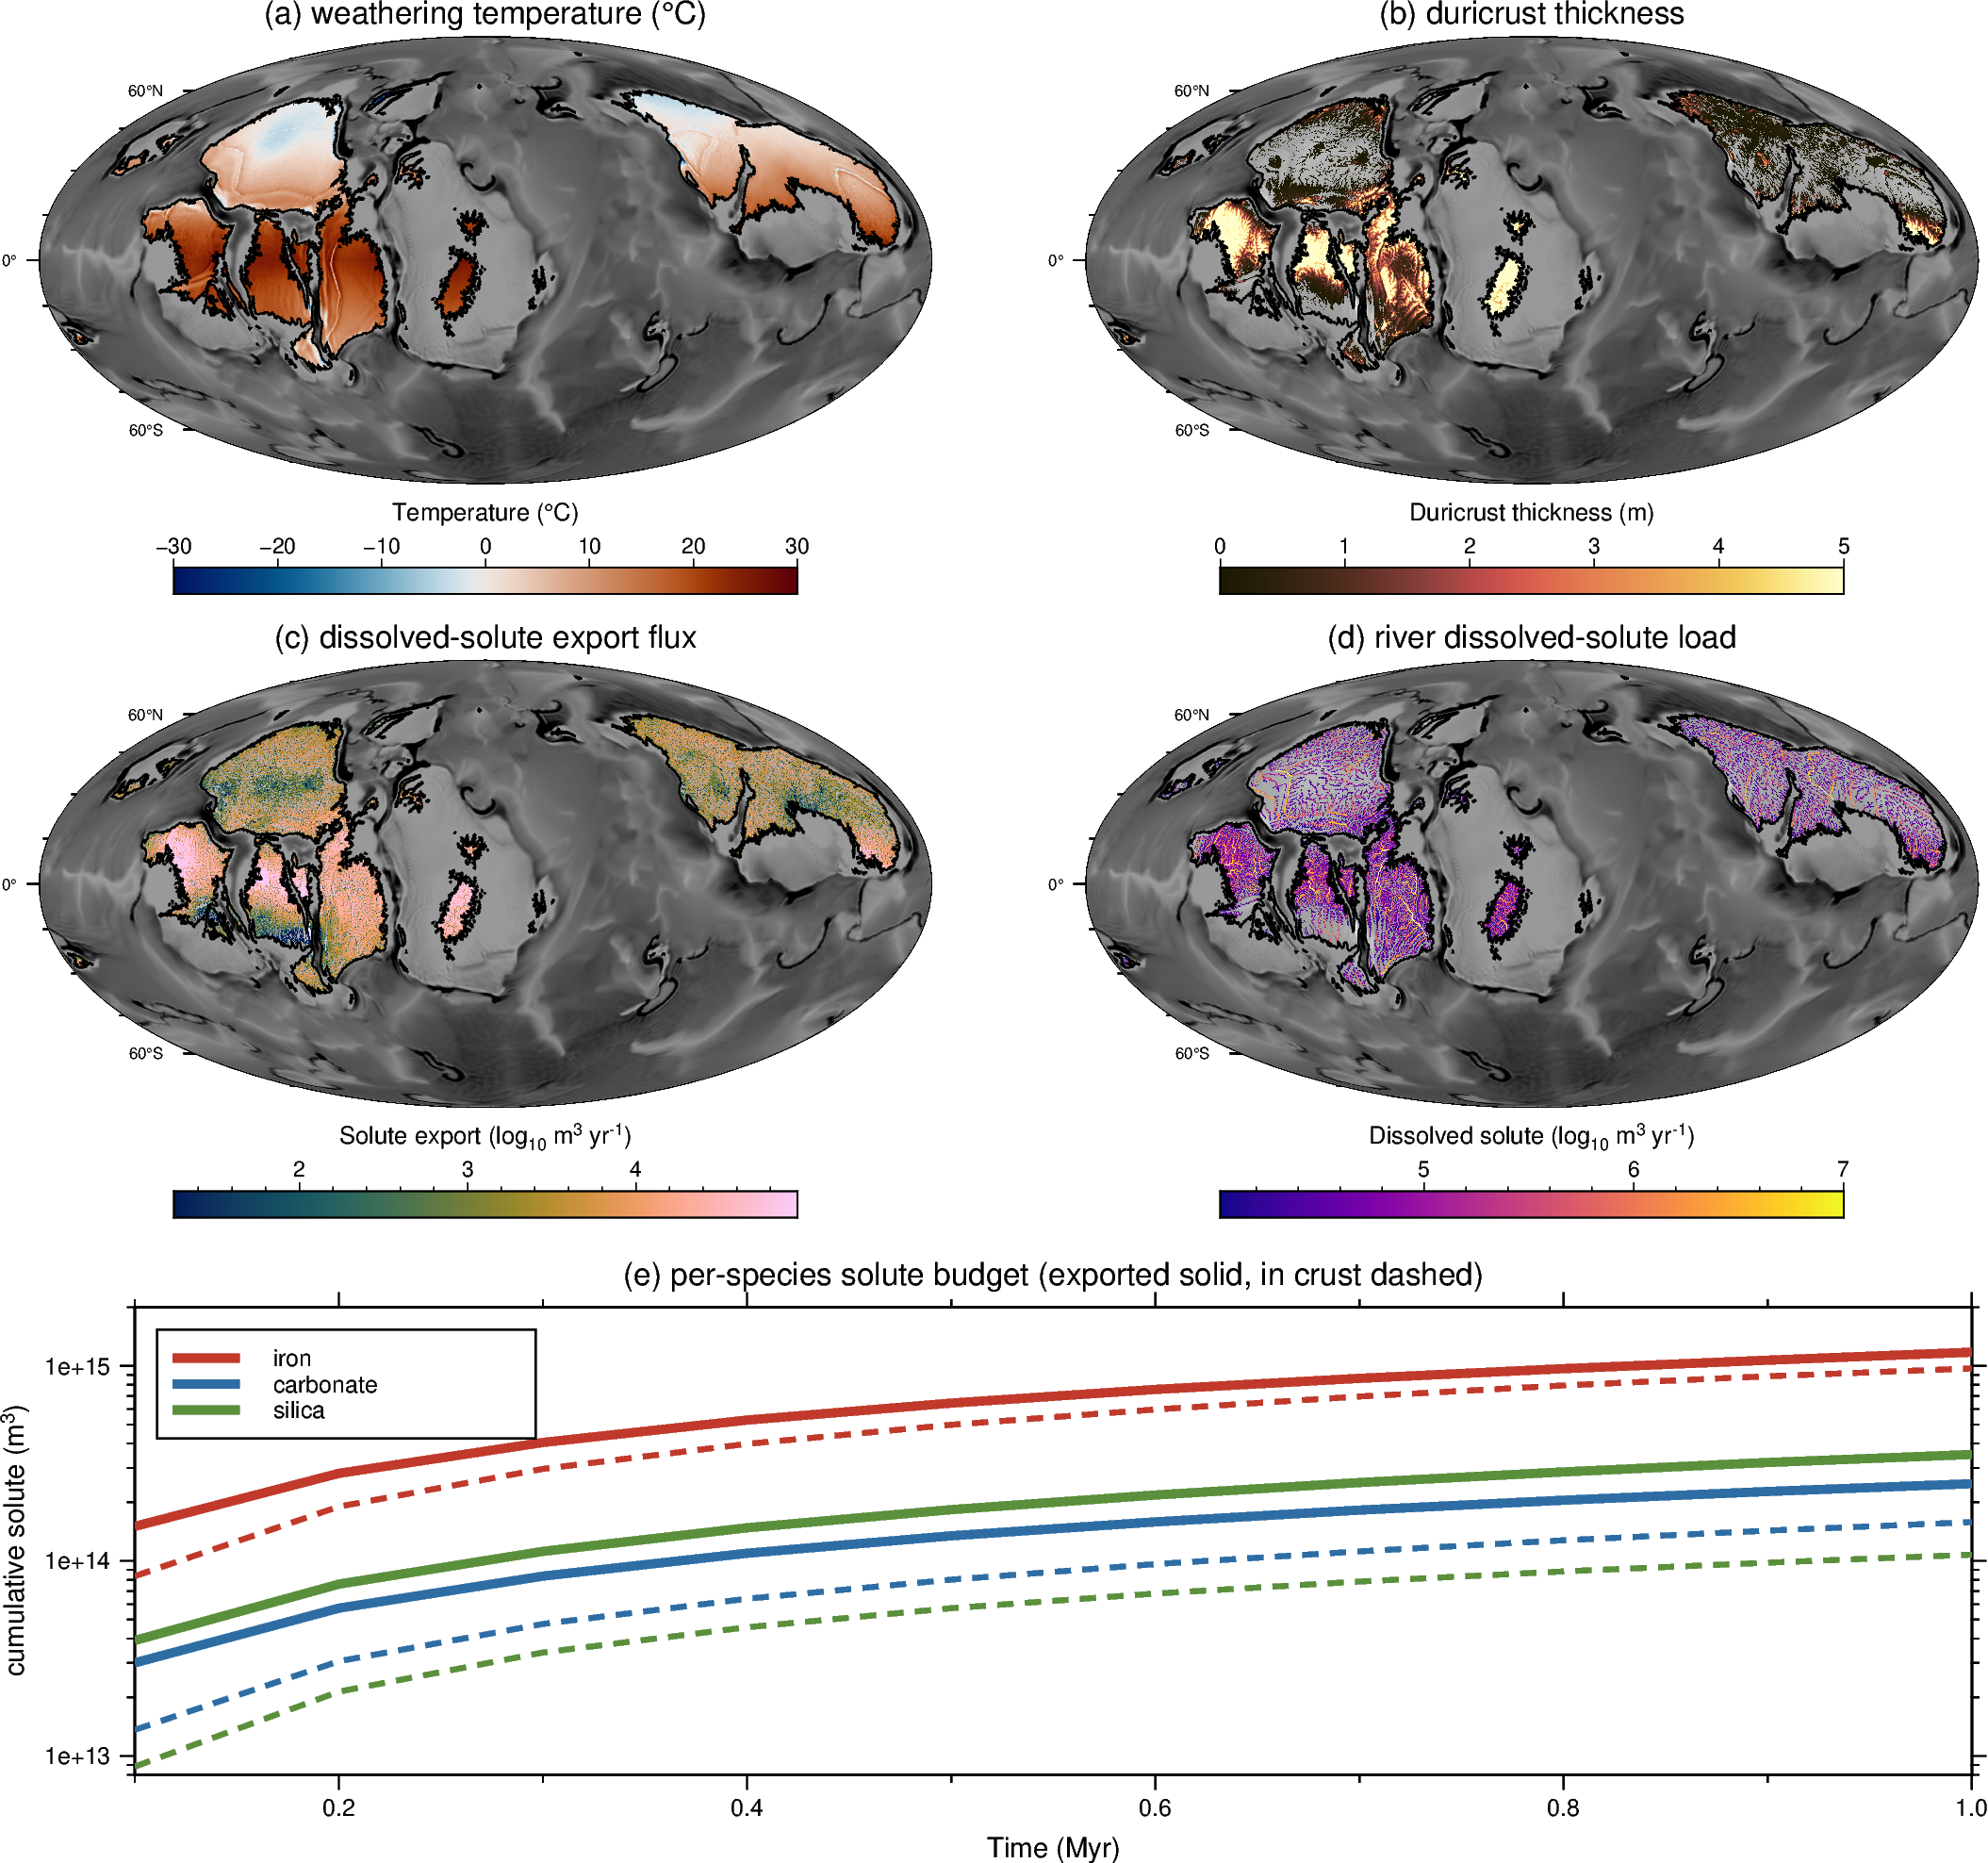

In [1]:
%matplotlib inline
import os
import numpy as np
import xarray as xr
from scipy.interpolate import griddata
import pygmt

EX = os.getcwd()
MESH = os.path.join(EX, "..", "continental_flux", "vars_25_80", "mesh.npz")

ds = xr.open_dataset(os.path.join(EX, "results/surface10.nc"))
elev = ds.elev
land = elev >= 0.0

# Per-species solute budget through time (domain-integrated, cumulative).
bud = np.genfromtxt(os.path.join(EX, "silico_geochem/gw_solute_budget.csv"),
                    delimiter=",", names=True)
tb = (bud["time"] - bud["time"][0]) / 1.0e6                    # Myr since start

# Duricrust thickness (land only), the per-node dissolved-solute EXPORT flux and the
# routed river dissolved-solute LOAD (both log10, land only).
duri = ds.duricrust.where(ds.duricrust > 0.05).where(land)
sf = np.log10(ds.soluteflux.where(ds.soluteflux > 1.0).where(land))
rs = np.log10(ds.riverSolute.where(ds.riverSolute > 1.0e4))

# Temperature forcing: per-vertex geochem_inputs.npz:temp mapped onto the grid.
v = np.load(MESH)["v"]
r = np.linalg.norm(v, axis=1)
mlon = np.degrees(np.arctan2(v[:, 1], v[:, 0]))
mlat = np.degrees(np.arcsin(np.clip(v[:, 2] / r, -1, 1)))
temp = np.load(os.path.join(EX, "geochem_inputs.npz"))["temp"]
LON, LAT = np.meshgrid(ds.lon.values, ds.lat.values)
tg = griddata((mlon, mlat), temp, (LON, LAT), method="nearest")
tempda = xr.DataArray(np.where(land.values, tg, np.nan), coords=[ds.lat, ds.lon], dims=["lat", "lon"])

PROJ, REG = "W8c", "d"
DX, DY = "9.4c", "-5.6c"
CBP = "jBC+o0c/-1.c+w5.6c/0.24c+h"
CB_FONT = dict(FONT_ANNOT_PRIMARY="9p,Helvetica,black", FONT_LABEL="10p,Helvetica,black")
LAT_FONT = "4p,Helvetica,black"
GRAY = "gray"; GRAY_SERIES = [-9000, 6000]

fig = pygmt.Figure()
pygmt.config(FONT="5p,Helvetica,black", FONT_TITLE="8p,Helvetica",
             MAP_TITLE_OFFSET="-6p", MAP_FRAME_PEN="0.6p")

def coast():
    fig.grdcontour(grid=elev, levels=0.1, limit=[0.0, 0.09], pen="0.4p,black")

def map_frame(title):
    fig.basemap(region=REG, projection=PROJ, frame=["xafg", title])
    with pygmt.config(FONT_ANNOT_PRIMARY=LAT_FONT):
        fig.basemap(region=REG, projection=PROJ, frame=["yafg"])

def graybg():
    pygmt.makecpt(cmap=GRAY, series=GRAY_SERIES)
    fig.grdimage(elev, cmap=True, frame=False)

# --- (a) temperature forcing (top-left) ------------------------------------
map_frame("+t(a) weathering temperature (@.C)")
graybg()
pygmt.makecpt(cmap="vik", series=[-30, 30])                   # warm = red, cold = blue
fig.grdimage(tempda, cmap=True, nan_transparent=True); coast()
with pygmt.config(**CB_FONT):
    fig.colorbar(position=CBP, frame=["a10", "x+lTemperature (@.C)"])

# --- (b) duricrust thickness (top-right) -----------------------------------
fig.shift_origin(xshift=DX)
map_frame("+t(b) duricrust thickness")
graybg()
pygmt.makecpt(cmap="lajolla", series=[0, 5])
fig.grdimage(duri, cmap=True, nan_transparent=True); coast()
with pygmt.config(**CB_FONT):
    fig.colorbar(position=CBP, frame=["a1", "x+lDuricrust thickness (m)"])

# --- (c) dissolved-solute export flux (bottom-left) ------------------------
fig.shift_origin(xshift="-" + DX, yshift=DY)
map_frame("+t(c) dissolved-solute export flux")
graybg()
pygmt.makecpt(cmap="batlow", series=[float(np.nanpercentile(sf.values, 2)),
                                     float(np.nanpercentile(sf.values, 99.5))])
fig.grdimage(sf, cmap=True, nan_transparent=True); coast()
with pygmt.config(**CB_FONT):
    fig.colorbar(position=CBP, frame="x+lSolute export (log@-10@- m@+3@+ yr@+-1@+)")

# --- (d) river dissolved-solute load (bottom-right) ------------------------
fig.shift_origin(xshift=DX)
map_frame("+t(d) river dissolved-solute load")
graybg()
pygmt.makecpt(cmap="plasma", series=[float(np.nanpercentile(rs.values, 2)),
                                     float(np.nanpercentile(rs.values, 99.5))])
fig.grdimage(rs, cmap=True, nan_transparent=True); coast()
with pygmt.config(**CB_FONT):
    fig.colorbar(position=CBP, frame="x+lDissolved solute (log@-10@- m@+3@+ yr@+-1@+)")

# --- (e) per-species solute budget through time (below the 2 x 2 maps) ------
SPP = [("iron", "#c0392b"), ("carbonate", "#2e6da4"), ("silica", "#5a8f3c")]
fig.shift_origin(xshift="-8.55c", yshift="-6c")
with pygmt.config(FONT_ANNOT_PRIMARY="6p,Helvetica,black", FONT_LABEL="7p,Helvetica,black",
                  FONT_TITLE="8p,Helvetica", MAP_TITLE_OFFSET="2p"):
    fig.basemap(region=[0.1, 1, 8e12, 2e15], projection="X16.5c/4.2cl",
                frame=["WSne+t(e) per-species solute budget (exported solid, in crust dashed)",
                       "xa0.2f0.1+lTime (Myr)", "ya1f3+lcumulative solute (m@+3@+)"])
    for sp, col in SPP:
        fig.plot(x=tb[1:], y=bud["oceanflux_" + sp][1:], pen=f"2.2p,{col}")        # exported to ocean
        fig.plot(x=tb[1:], y=bud["precipitated_" + sp][1:], pen=f"1.4p,{col},4_3")  # locked in crust
    # compact legend of the three species colours
    leg = "\n".join(f"S 0.3c - 0.6c - 2.2p,{c} 0.9c {sp}" for sp, c in SPP)
    fig.legend(spec=__import__("io").StringIO(leg), position="jTL+o0.2c+w3.4c", box="+gwhite+p0.5p")

# fig.savefig("fig_ex_globalgeochem.pdf")
# fig.savefig("fig_ex_globalgeochem.png", dpi=200)
print(f"wrote fig_ex_globalgeochem.pdf / .png | temp {np.nanmin(tempda.values):.0f}..{np.nanmax(tempda.values):.0f} C | "
      f"duri<= {float(ds.duricrust.max()):.1f} m | soluteflux max {float(np.nanmax(ds.soluteflux)):.2g} m3/yr")
fig.show()

## Solute budget

The domain-integrated budget of each dissolved species, written by goSPL at every output (`silico_geochem/gw_solute_budget.csv`): cumulative dissolved, precipitated into the duricrust and exported to the rivers. The last line closes the budget: dissolved = precipitated + exported.

In [2]:
import pandas as pd
bud = pd.read_csv('silico_geochem/gw_solute_budget.csv')
print(bud.tail(3).to_string(index=False))
last = bud.iloc[-1]
for sp in [c[len('dissolved_'):] for c in bud.columns if c.startswith('dissolved_')]:
    d, p, o = last['dissolved_' + sp], last['precipitated_' + sp], last['oceanflux_' + sp]
    print('%-10s dissolved %.4g  precipitated %.4g  exported %.4g  closure %.1e' % (sp, d, p, o, (d - p - o) / d if d else 0.0))

       time  dissolved_iron  precipitated_iron  oceanflux_iron  riverToOcean_iron  marine_iron  dissolved_carbonate  precipitated_carbonate  oceanflux_carbonate  riverToOcean_carbonate  marine_carbonate  dissolved_silica  precipitated_silica  oceanflux_silica  riverToOcean_silica  marine_silica
250800000.0    1.759850e+15       7.932650e+14    9.665850e+14        833574000.0 6.867220e+14         3.322120e+14            1.273700e+14         2.048410e+14             139256000.0      1.308810e+14      3.742610e+14         8.826340e+13      2.859980e+14          238028000.0   1.936370e+14
250900000.0    1.954500e+15       8.849430e+14    1.069550e+15        833935000.0 7.693860e+14         3.696690e+14            1.427300e+14         2.269390e+14             136625000.0      1.447070e+14      4.171310e+14         9.796040e+13      3.191710e+14          230003000.0   2.168040e+14
251000000.0    2.143680e+15       9.704350e+14    1.173240e+15        864922000.0 8.554020e+14         4.064160e